# 第二輪資料：剔除正常群

用第一輪的分群結果（1to4、Latent16、min_cluster_size=180），把判斷為正常的群拿掉，存成新的資料集給第二輪 AE 用。

- noise（-1）都保留
- 不會動到第一輪的檔案

## 0. 套件與路徑

In [4]:
import os
import re
import json
import shutil
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.format import open_memmap
from tqdm.auto import tqdm

L = 256
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]

BASE      = r"D:\pva_training\cache"
DATA      = r"D:\pva_training\data\training_data"
SRC_DIR   = os.path.join(DATA, f"1to4_PC-AC_L{L}")                             # 第一階段資料
LAB_FILE  = os.path.join(BASE, "hdbscan_labels_mcs180_msNone_n899454.npy")     # 第一階段群號
UMAP_FILE = os.path.join(BASE, "1to4_umap_cache.npz")                          # 第一階段 UMAP（5 維分群、2 維畫圖）
OUT_DIR   = os.path.join(DATA, f"1to4_PC-AC_L{L}_stage2")                      # 輸出，換清單時記得改名

## 1. 讀取第一階段資料

In [5]:
X  = np.load(os.path.join(SRC_DIR, "X.npy"), mmap_mode="r")      # mmap 讀
kb = pd.read_csv(os.path.join(SRC_DIR, "kb.csv"), dtype={"rec": str, "mode": str})
lab = np.load(LAB_FILE)
d = np.load(UMAP_FILE)
E_fit, E2_fit = d["E_fit"], d["E2_fit"]

N = len(lab)
assert len(X) == len(kb) == len(E_fit) == len(E2_fit) == N, "X、kb、群號、UMAP 的筆數不一致"

patient = kb["rec"].to_numpy()
n_clu = lab.max() + 1
sizes = pd.Series(lab).value_counts()

print("X shape  =", X.shape)
print(f"群數 = {n_clu}，noise = {sizes.get(-1, 0):,} 口（{sizes.get(-1, 0) / N:.2%}）")

X shape  = (899454, 3, 256)
群數 = 62，noise = 29,958 口（3.33%）


## 2. 輸入要剔除的群號

逗號、空白、換行都可以，連續的可以寫範圍，例如 `5-9`。

目前是人工判讀為正常的 16 群（remove16）；remove18 是再加上 12、21。換清單時 `OUT_DIR` 也要改名，不然會蓋掉。

In [6]:
REMOVE_TEXT = '''
4, 6, 7, 9, 16, 17, 19, 44, 50, 53, 54, 56, 57, 58, 60, 61
'''

In [7]:
def parse_clusters(text):
    # "0, 3, 5-9" 轉成群號 list
    out = []
    for tok in re.split(r"[,\s，、]+", text.strip()):
        if not tok:
            continue
        m = re.fullmatch(r"(\d+)\s*-\s*(\d+)", tok)
        if m:
            a, b = int(m.group(1)), int(m.group(2))
            out.extend(range(min(a, b), max(a, b) + 1))
        else:
            out.append(int(tok))
    return out

raw = parse_clusters(REMOVE_TEXT)
REMOVE_CLUSTERS = sorted(set(raw))

assert REMOVE_CLUSTERS, "REMOVE_TEXT 是空的，請先輸入要剔除的群號"
assert -1 not in REMOVE_CLUSTERS, "noise（-1）不能剔除"
bad = [c for c in REMOVE_CLUSTERS if c < 0 or c >= n_clu]
assert not bad, f"這些群號不存在（有效範圍 0–{n_clu - 1}）：{bad}"
dup = sorted({c for c in raw if raw.count(c) > 1})
if dup:
    print(f"注意：這些群號重複輸入，已自動去除重複：{dup}")

print(f"要剔除 {len(REMOVE_CLUSTERS)} 群：{REMOVE_CLUSTERS}")

要剔除 16 群：[4, 6, 7, 9, 16, 17, 19, 44, 50, 53, 54, 56, 57, 58, 60, 61]


## 3. 檢查要剔除的群

In [8]:
# 每群的口數與病人組成
ratio = pd.crosstab(lab, patient, normalize="index")
tbl = pd.DataFrame({
    "n":           sizes.reindex(REMOVE_CLUSTERS).values,
    "top_patient": ratio.idxmax(axis=1).reindex(REMOVE_CLUSTERS).values,
    "top_share":   ratio.max(axis=1).reindex(REMOVE_CLUSTERS).values,
}, index=pd.Index(REMOVE_CLUSTERS, name="cluster"))

n_rm = int(tbl["n"].sum())
print(f"這 {len(tbl)} 群共 {n_rm:,} 口（占全部 {n_rm / N:.1%}）\n")
with pd.option_context("display.max_rows", None):
    print(tbl.sort_values("n", ascending=False)
             .to_string(formatters={"n": "{:,}".format, "top_share": "{:.1%}".format}))

這 16 群共 143,782 口（占全部 16.0%）

              n top_patient top_share
cluster                              
7       101,283           4     99.9%
19       12,621           1    100.0%
61        9,198           1    100.0%
6         4,980           4    100.0%
4         3,999           1     99.9%
17        2,594           2    100.0%
58        1,397           1    100.0%
16        1,335           2    100.0%
9         1,210           3     99.9%
60        1,156           1    100.0%
57        1,091           1    100.0%
53          824           1     99.9%
56          659           1    100.0%
50          511           1    100.0%
54          466           1    100.0%
44          458           1    100.0%


In [9]:
# 各病人被剔除多少
in_remove = np.isin(lab, REMOVE_CLUSTERS)
pt = pd.DataFrame({"total": pd.Series(patient).value_counts(),
                   "in_removed_clusters": pd.Series(patient[in_remove]).value_counts()}).fillna(0).astype(int)
pt["share"] = pt["in_removed_clusters"] / pt["total"]
print(pt.sort_index().to_string(formatters={"share": "{:.1%}".format}))

    total  in_removed_clusters share
1  131138                32382 24.7%
2  458853                 3951  0.9%
3    3097                 1262 40.7%
4  306366               106187 34.7%


### 3-1 看一下要剔除的群

每群隨機畫 `N_PICK` 口，黑線是中位數，確認沒選錯。不想畫就把 `SHOW_PLOTS` 設 `False`。

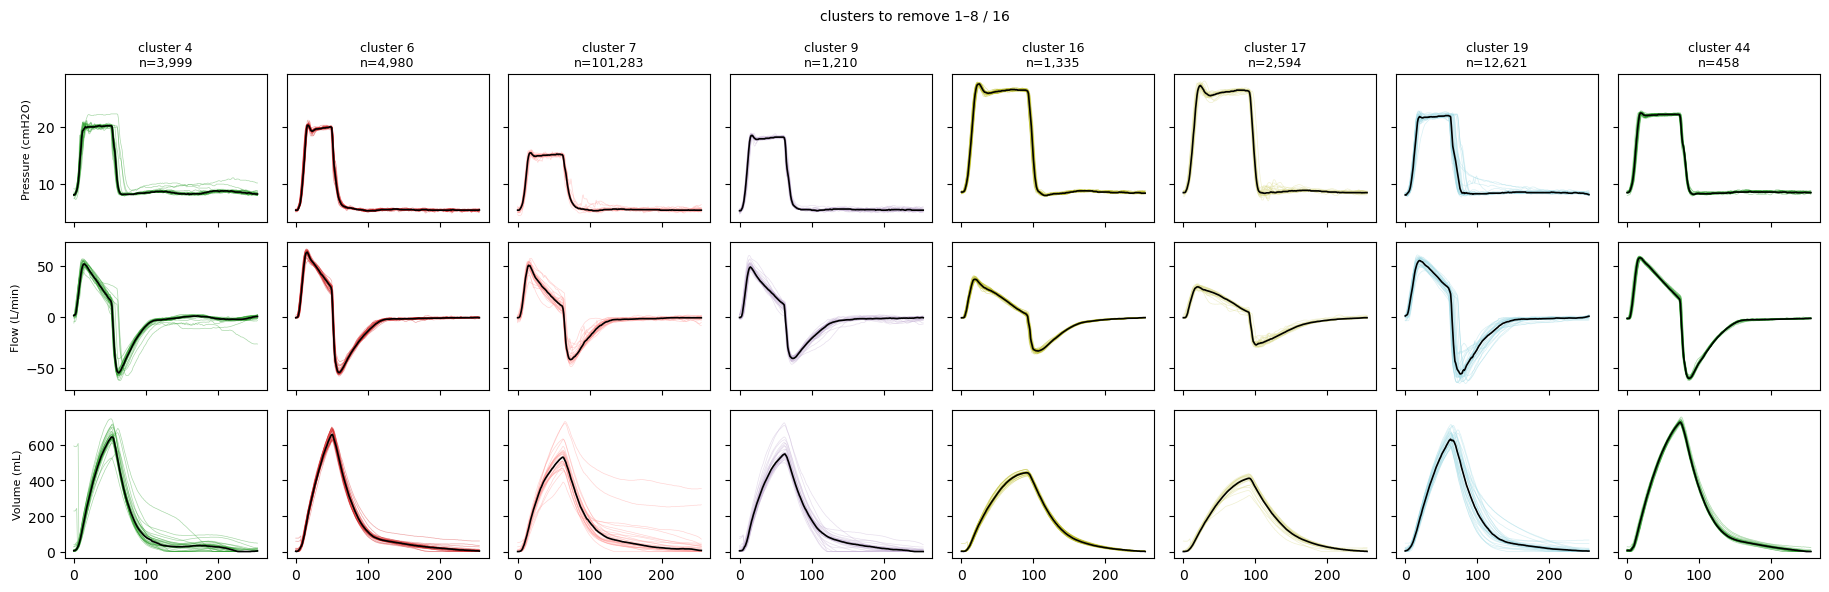

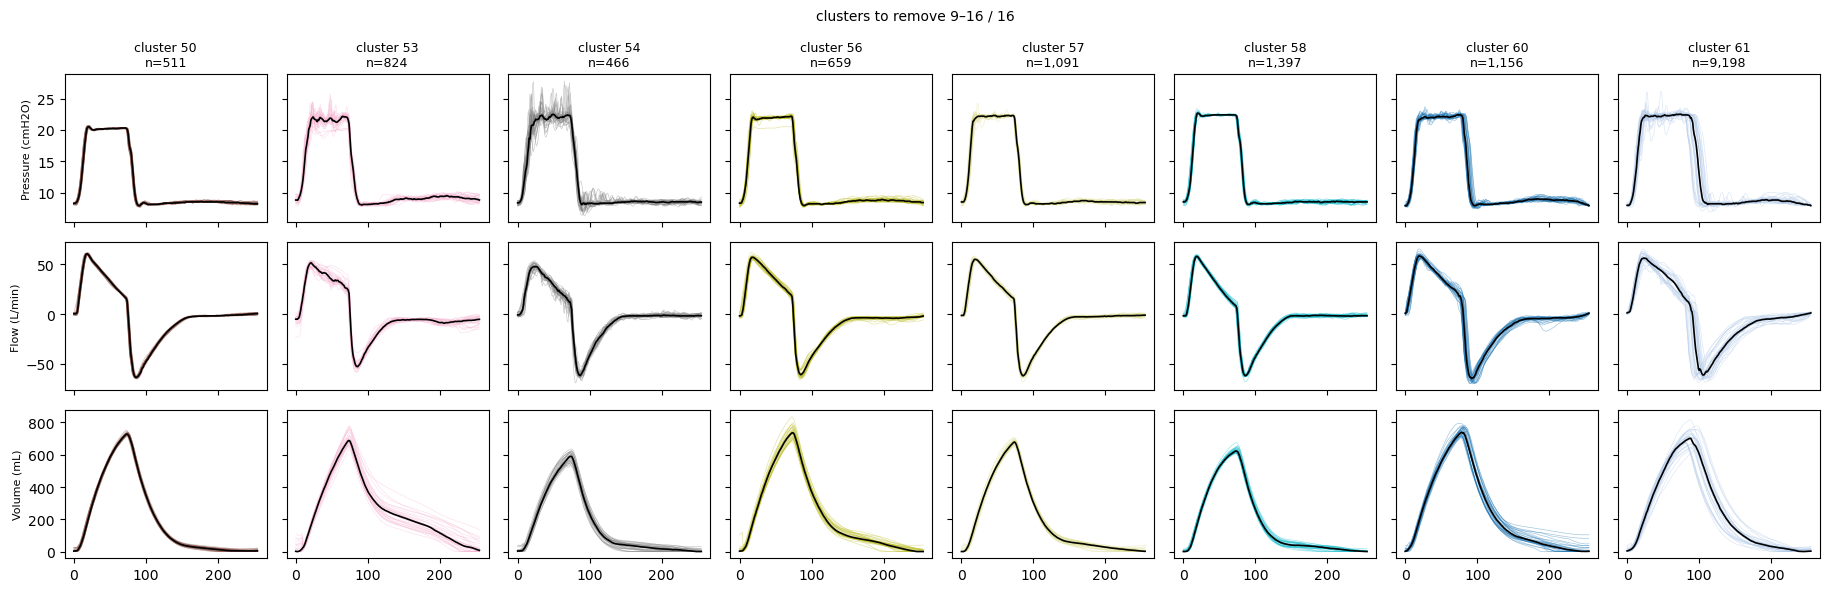

In [10]:
SHOW_PLOTS = True
PER_FIG = 8
N_PICK  = 30
rng_plot = np.random.default_rng(0)

if SHOW_PLOTS:
    for p in range(0, len(REMOVE_CLUSTERS), PER_FIG):
        page = REMOVE_CLUSTERS[p:p + PER_FIG]
        fig, ax = plt.subplots(3, len(page), figsize=(2.3 * len(page), 6), sharex=True, sharey="row", squeeze=False)
        for j, c in enumerate(page):
            members = np.flatnonzero(lab == c)
            pick = np.sort(rng_plot.choice(members, size=min(N_PICK, len(members)), replace=False))
            w = np.asarray(X[pick])
            col = plt.cm.tab20(c % 20)
            for i in range(3):
                ax[i, j].plot(w[:, i].T, color=col, lw=0.5, alpha=0.4)
                ax[i, j].plot(np.median(w[:, i], axis=0), color="k", lw=1.2)
                if j == 0:
                    ax[i, j].set_ylabel(CH[i], fontsize=8)
            ax[0, j].set_title(f"cluster {c}\nn={sizes[c]:,}", fontsize=9)
        fig.suptitle(f"clusters to remove {p + 1}–{p + len(page)} / {len(REMOVE_CLUSTERS)}", fontsize=10)
        plt.tight_layout()
        plt.show()

## 4. 救回邊緣呼吸（選用）

被剔除的群裡，離群中心最遠的可能藏著不同步，可以先留下來。距離是在 5 維 UMAP（`E_fit`）上算到群中心的距離，`EDGE_PCT = 95` 就是每群留最遠的 5%。因為沒存 HDBSCAN 的 membership probability，所以用距離代替。

目前 `RESCUE_EDGE = False`，沒有救回。

In [11]:
RESCUE_EDGE = False
EDGE_PCT    = 95

rescued = np.zeros(N, dtype=bool)
if RESCUE_EDGE:
    idx = np.flatnonzero(in_remove)
    g = lab[idx]
    center = pd.DataFrame(E_fit[idx]).groupby(g).median()                      # 每群中心
    dist = np.linalg.norm(E_fit[idx] - center.loc[g].to_numpy(), axis=1)
    thr = pd.Series(dist).groupby(g).transform(lambda v: v.quantile(EDGE_PCT / 100)).to_numpy()
    rescued[idx[dist >= thr]] = True

remove = in_remove & ~rescued
keep_idx = np.flatnonzero(~remove)

print(f"被剔除群的呼吸：{in_remove.sum():,}")
print(f"其中救回的邊緣呼吸：{rescued.sum():,}")
print(f"實際剔除：{remove.sum():,}")

被剔除群的呼吸：143,782
其中救回的邊緣呼吸：0
實際剔除：143,782


## 5. 結果摘要

In [12]:
reason = np.select(
    [remove, lab < 0, rescued],
    ["removed", "noise", "rescued_edge"],
    default="kept_cluster",
)

n_removed = int(remove.sum())
n_keep = len(keep_idx)
print(f"全部：{N:,} 口")
print(f"剔除：{n_removed:,}（{n_removed / N:.1%}）")
print(f"保留：{n_keep:,}（{n_keep / N:.1%}）  ← 第二階段資料\n")

summary = pd.crosstab(pd.Series(patient, name="patient"), pd.Series(reason, name="reason"),
                      margins=True, margins_name="合計")
summary["keep_rate"] = 1 - summary.get("removed", 0) / summary["合計"]
print(summary.to_string(formatters={"keep_rate": "{:.1%}".format}))

ub = 1 - 0.05 ** (1 / 100)
print(f"\n若每群抽樣 100 口皆正常：每群不同步比例 95% 上限 {ub:.2%}，"
      f"誤刪不同步最壞情況約 {int(n_removed * ub):,} 口")

全部：899,454 口
剔除：143,782（16.0%）
保留：755,672（84.0%）  ← 第二階段資料

reason   kept_cluster  noise  removed      合計 keep_rate
patient                                                
1               69581  29175    32382  131138     75.3%
2              454526    376     3951  458853     99.1%
3                1657    178     1262    3097     59.3%
4              199950    229   106187  306366     65.3%
合計             725714  29958   143782  899454     84.0%

若每群抽樣 100 口皆正常：每群不同步比例 95% 上限 2.95%，誤刪不同步最壞情況約 4,243 口


## 6. 在第一輪的 2D UMAP 上看剔除了哪些

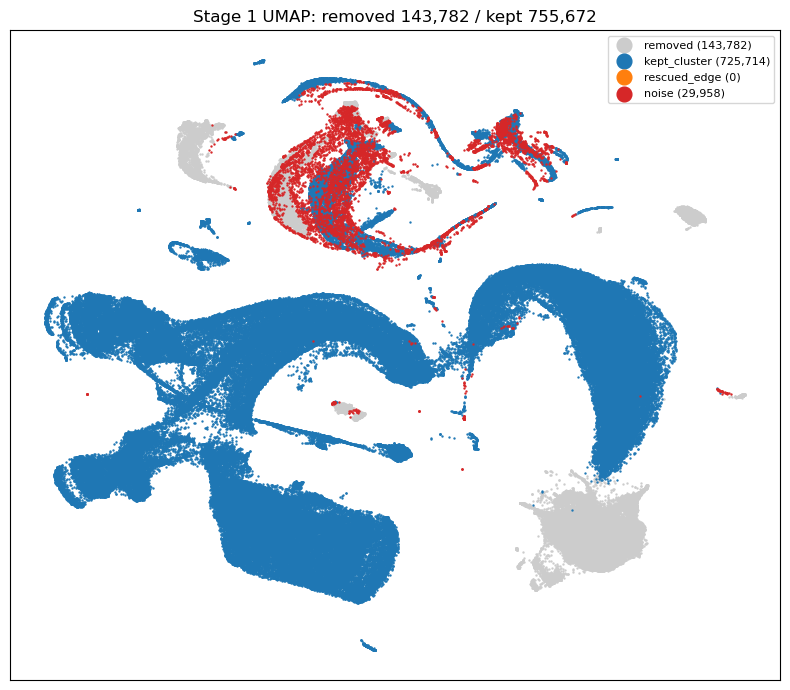

In [13]:
rng_umap = np.random.default_rng(0)
sub = rng_umap.choice(N, size=min(N, 200_000), replace=False)                 # 點太多，抽樣畫
colors = {"removed": "#cccccc", "kept_cluster": "#1f77b4", "rescued_edge": "#ff7f0e", "noise": "#d62728"}

fig, ax = plt.subplots(figsize=(8, 7))
for r, c in colors.items():
    m = sub[reason[sub] == r]
    ax.scatter(*E2_fit[m].T, s=0.5, c=c, rasterized=True, label=f"{r} ({(reason == r).sum():,})")
ax.legend(markerscale=15, fontsize=8)
ax.set_title(f"Stage 1 UMAP: removed {n_removed:,} / kept {n_keep:,}")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 7. 存檔

存到 `OUT_DIR`，格式跟第一輪一樣（`X.npy`、`kb.csv`、`dropped.csv`），另外多存：

- `kb.csv` 多 `orig_idx`、`stage1_cluster`、`stage1_reason` 三欄
- `keep_idx.npy`：留下的口在第一輪 X 的位置
- `stage2_info.json`：剔除哪些群、口數

資料夾已經有 `X.npy` 會停下來，要覆蓋就把 `OVERWRITE` 改成 `True`。

In [14]:
OVERWRITE = False
CHUNK = 50_000

x_path = os.path.join(OUT_DIR, "X.npy")
if os.path.exists(x_path) and not OVERWRITE:
    raise FileExistsError(f"{x_path} 已存在；確定要覆蓋請把 OVERWRITE 改成 True")
os.makedirs(OUT_DIR, exist_ok=True)

# 波形分批寫
gb = n_keep * np.prod(X.shape[1:]) * X.dtype.itemsize / 1e9
print(f"寫出 X.npy：{(n_keep,) + X.shape[1:]}，約 {gb:.2f} GB")
Xo = open_memmap(x_path, mode="w+", dtype=X.dtype, shape=(n_keep,) + X.shape[1:])
for s in tqdm(range(0, n_keep, CHUNK)):
    Xo[s:s + CHUNK] = X[keep_idx[s:s + CHUNK]]
Xo.flush()
del Xo

# kb.csv，多加第一階段的對應欄位
kb_out = kb.iloc[keep_idx].copy()
kb_out["orig_idx"] = keep_idx
kb_out["stage1_cluster"] = lab[keep_idx]
kb_out["stage1_reason"] = reason[keep_idx]
kb_out.to_csv(os.path.join(OUT_DIR, "kb.csv"), index=False)

# 其他
shutil.copy(os.path.join(SRC_DIR, "dropped.csv"), os.path.join(OUT_DIR, "dropped.csv"))
np.save(os.path.join(OUT_DIR, "keep_idx.npy"), keep_idx)

info = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "source_dir": SRC_DIR,
    "label_file": LAB_FILE,
    "remove_clusters": [int(c) for c in REMOVE_CLUSTERS],
    "n_remove_clusters": len(REMOVE_CLUSTERS),
    "rescue_edge": RESCUE_EDGE,
    "edge_pct": EDGE_PCT if RESCUE_EDGE else None,
    "n_total": int(N),
    "n_removed": n_removed,
    "n_rescued": int(rescued.sum()),
    "n_noise_kept": int((lab < 0).sum()),
    "n_keep": int(n_keep),
}
with open(os.path.join(OUT_DIR, "stage2_info.json"), "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

print("已存到", OUT_DIR)
print(json.dumps(info, ensure_ascii=False, indent=2))

寫出 X.npy：(755672, 3, 256)，約 2.32 GB


  0%|          | 0/16 [00:00<?, ?it/s]

已存到 D:\pva_training\data\training_data\1to4_PC-AC_L256_stage2
{
  "created": "2026-11-16T18:20:48",
  "source_dir": "D:\\pva_training\\data\\training_data\\1to4_PC-AC_L256",
  "label_file": "D:\\pva_training\\cache\\hdbscan_labels_mcs180_msNone_n899454.npy",
  "remove_clusters": [
    4,
    6,
    7,
    9,
    16,
    17,
    19,
    44,
    50,
    53,
    54,
    56,
    57,
    58,
    60,
    61
  ],
  "n_remove_clusters": 16,
  "rescue_edge": false,
  "edge_pct": null,
  "n_total": 899454,
  "n_removed": 143782,
  "n_rescued": 0,
  "n_noise_kept": 29958,
  "n_keep": 755672
}


## 8. 檢查存檔

In [15]:
X2  = np.load(os.path.join(OUT_DIR, "X.npy"), mmap_mode="r")
kb2 = pd.read_csv(os.path.join(OUT_DIR, "kb.csv"), dtype={"rec": str, "mode": str})
k2  = np.load(os.path.join(OUT_DIR, "keep_idx.npy"))

assert len(X2) == len(kb2) == len(k2) == n_keep
assert np.array_equal(kb2["orig_idx"].to_numpy(), k2)
assert not np.isin(kb2["orig_idx"], np.flatnonzero(remove)).any(), "存檔裡出現了應該剔除的呼吸"

# 抽 1000 口跟第一階段比對
chk = np.sort(np.random.default_rng(1).choice(n_keep, size=min(1000, n_keep), replace=False))
assert np.array_equal(np.asarray(X2[chk]), np.asarray(X[k2[chk]]))
assert (kb2["breath_id"].to_numpy()[chk] == kb["breath_id"].to_numpy()[k2[chk]]).all()

print("驗證通過：X2", X2.shape, "，kb2", kb2.shape)

驗證通過：X2 (755672, 3, 256) ，kb2 (755672, 13)


## 下一步

接著跑 `autoencoder_round2.ipynb`：`CACHE` 指到這次的輸出資料夾，`SAVE_PATH` 換一個名字。之後 `clustering_round2.ipynb` 的 UMAP 快取和圖的資料夾也要換名字，不然會讀到舊的。